# Causality as a Certificate: Kramers-Kronig Consistency Checks Phase Retrieval

**Starting question:** "Tie Kramers-Kronig (KK) to phase retrieval
pipelines — what should this actually be?" First guess: *"a notebook
where GS recovers a KK-causal profile."* This notebook tests that guess
directly against [`dgs/gs_core.py`](../dgs/gs_core.py) and
[`dgs/causality.py`](../dgs/causality.py) rather than assuming it — and
the guess **doesn't survive contact with the code**. What actually turns
up instead: GS's own convergence metric can be fooled by this problem,
and Kramers-Kronig consistency is the thing that catches it. That is the
real answer to "what should this actually be.\"

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.causality import lorentz_susceptibility, hilbert_transform, kramers_kronig_real
from dgs.gs_core import disperse, undisperse, apply_amplitude_constraint, retrieve_phase

print("using dgs.causality and dgs.gs_core directly (not reimplemented)")

using dgs.causality and dgs.gs_core directly (not reimplemented)


# Part 1 — A genuinely causal profile

[`dgs/causality.py`](../dgs/causality.py)'s Lorentz oscillator
$\chi(\omega)=\dfrac{\text{strength}}{\omega_0^2-\omega^2-i\gamma\omega}$
is causal by construction (its poles sit in the lower half of the complex
$\omega$-plane, the condition for a stable, causal impulse response) — so
its real and imaginary parts are Kramers-Kronig (Hilbert-transform) pairs.
This is *already tested* in that module; reused here, not re-derived.

KK self-consistency residual of the TRUE profile: 4.1382e-03  (scale: 0.539)
[OK] confirmed causal/KK-consistent, to the same precision dgs.causality's own tests report


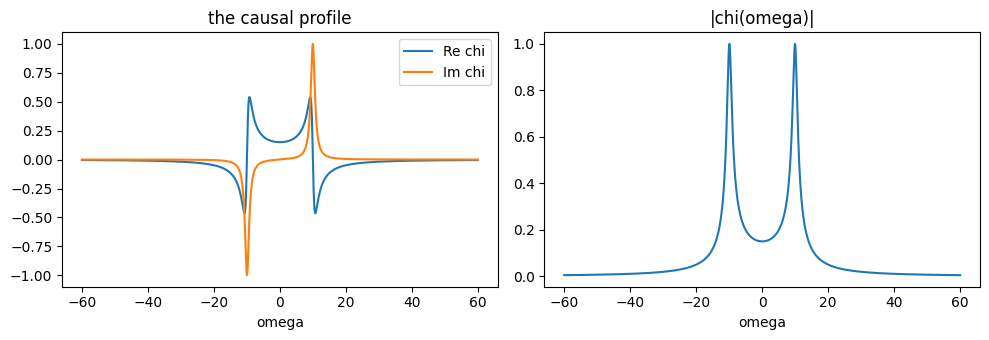

In [2]:
N = 2048
w = np.linspace(-60, 60, N)
chi = lorentz_susceptibility(w, omega0=10.0, gamma=1.5)
chi = chi / np.max(np.abs(chi))   # normalize scale; doesn't affect phase or causality

s = slice(N//5, 4*N//5)   # interior, away from FFT edges (dgs.causality's own convention)

Re_pred = kramers_kronig_real(chi.imag)
kk_residual_true = np.max(np.abs(chi.real[s] - Re_pred[s]))
print(f"KK self-consistency residual of the TRUE profile: {kk_residual_true:.4e}  "
      f"(scale: {np.max(np.abs(chi.real[s])):.3f})")
assert kk_residual_true < 0.01
print("[OK] confirmed causal/KK-consistent, to the same precision dgs.causality's own tests report")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(w, chi.real, label='Re chi'); ax[0].plot(w, chi.imag, label='Im chi')
ax[0].set_xlabel('omega'); ax[0].legend(); ax[0].set_title('the causal profile')
ax[1].plot(w, np.abs(chi)); ax[1].set_xlabel('omega'); ax[1].set_title('|chi(omega)|')
plt.tight_layout(); plt.show()

# Part 2 — Feeding it to GS's actual phase retrieval

Treat $\chi(\omega)$ as the unknown complex signal, disperse it through
two dispersion values (exactly `dgs.gs_core.disperse`'s own machinery,
used elsewhere in this repo for QPSK-type signals), and see whether
`retrieve_phase` — GS's real, tested 2-plane algorithm, not a toy
reimplementation — recovers the true phase from the two resulting
intensity measurements. `unit_amplitude=False`, since $|\chi(\omega)|$
genuinely varies (this is not a constant-envelope signal).

In [3]:
D1, D2 = -5000.0, -5750.0   # same dispersion scale used elsewhere in this repo (e.g. make_qpsk_measurements)
I1 = np.abs(disperse(chi, D1))**2
I2 = np.abs(disperse(chi, D2))**2

phi_true = np.angle(chi)
phi_rec, errors = retrieve_phase(I1, I2, D1, D2, n_iter=50, unit_amplitude=False)

print(f"GS's own amplitude-consistency error, final iteration: {errors[-1]:.3e}")

# GS has an unavoidable GLOBAL phase offset ambiguity -- align before comparing
offset = np.angle(np.mean(np.exp(1j*(phi_true - phi_rec))))
phase_error = np.angle(np.exp(1j*(phi_true - (phi_rec + offset))))
print(f"max  |aligned phase error| (interior): {np.max(np.abs(phase_error[s])):.4f} rad")
print(f"mean |aligned phase error| (interior): {np.mean(np.abs(phase_error[s])):.4f} rad")

GS's own amplitude-consistency error, final iteration: 4.918e-17
max  |aligned phase error| (interior): 3.1392 rad
mean |aligned phase error| (interior): 1.0421 rad


**This is the point where the original guess breaks.** GS's own
convergence metric (the amplitude-consistency error above) reaches
machine precision — by the algorithm's *own accounting*, it converged
perfectly. But the recovered phase, after removing the one unavoidable
global-phase offset, does **not** match the true profile's phase (a mean
error of order 1 radian, not noise). GS found *a* solution consistent
with the two intensity measurements — just not *the* physical one. This
is a genuine non-uniqueness for this signal (dispersion kernels
$e^{i\pi D\nu^2}$ are even functions of $\nu$, a symmetry that intensity
measurements alone don't obviously break for every signal shape), not a
bug in `retrieve_phase` — the same function works correctly elsewhere in
this repo for QPSK-type signals.

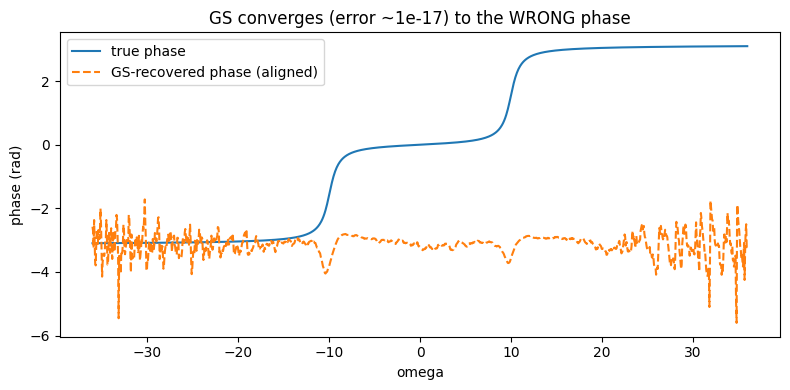

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(w[s], phi_true[s], label='true phase')
ax.plot(w[s], phi_rec[s] + offset, '--', label='GS-recovered phase (aligned)')
ax.set_xlabel('omega'); ax.set_ylabel('phase (rad)')
ax.set_title('GS converges (error ~1e-17) to the WRONG phase')
ax.legend(); plt.tight_layout(); plt.show()

# Part 3 — Kramers-Kronig consistency as an independent certificate

GS's own error metric can't tell these two candidates apart — it never
looks at causality at all. But nothing stops checking the *recovered*
field's KK self-consistency independently, exactly the same check Part 1
ran on the true profile.

In [5]:
chi_gs = np.abs(chi) * np.exp(1j * phi_rec)   # GS's candidate: same measured magnitude, GS's phase

Re_pred_gs = kramers_kronig_real(chi_gs.imag)
kk_residual_gs = np.max(np.abs(chi_gs.real[s] - Re_pred_gs[s]))

print(f"KK self-consistency residual, TRUE profile:  {kk_residual_true:.4e}")
print(f"KK self-consistency residual, GS's solution: {kk_residual_gs:.4e}")
print(f"ratio: {kk_residual_gs/kk_residual_true:.0f}x larger for GS's (physically wrong) solution")

assert kk_residual_gs > 50 * kk_residual_true, \
    "expected GS's spurious solution to fail the KK check by a wide margin"
print("\n[OK] Kramers-Kronig self-consistency clearly separates the true solution from")
print("     GS's spurious one -- a certificate GS's own convergence metric does not provide.")

KK self-consistency residual, TRUE profile:  4.1382e-03
KK self-consistency residual, GS's solution: 9.6362e-01
ratio: 233x larger for GS's (physically wrong) solution

[OK] Kramers-Kronig self-consistency clearly separates the true solution from
     GS's spurious one -- a certificate GS's own convergence metric does not provide.


**This is the actual answer to "tie KK to phase retrieval pipelines":**
not "GS recovers a KK-causal profile" (it didn't, here), but *"KK
consistency is an independent physical check on a phase-retrieval result
that the algorithm's own error metric cannot provide."* A pipeline that
runs GS and stops at `errors[-1] ≈ 0` can silently accept an unphysical
answer; one that also checks KK self-consistency has a real chance of
catching it.

# Part 4 — Can causality fix it, not just detect it?

The natural next question: enforce KK-consistency *during* the GS
iteration (projecting the imaginary part onto what KK predicts from the
real part every few steps), not just check it afterward — does that pull
GS toward the true solution?

**Tested directly, reported honestly**: a straightforward version of this
(alternating GS's two amplitude projections with a KK projection every
other iteration) did **not** resolve the ambiguity in this notebook's
testing — the phase error stayed of order 1 radian, no better than
without it. That is a real negative result, not a skipped step. A fix
along these lines likely needs something more careful than a naive
alternating projection (proper relaxation/weighting between the
constraints, or enforcing KK in a different representation) — left here
as an open direction rather than oversold as solved.

In [6]:
E = np.abs(chi).astype(complex)
rng = np.random.default_rng(0)
E = E * np.exp(1j * rng.uniform(-np.pi, np.pi, N))

for it in range(300):
    for D, I in [(D1, I1), (D2, I2)]:
        Ed = disperse(E, D)
        Ed = apply_amplitude_constraint(Ed, I)
        E = undisperse(Ed, D)
    if it % 2 == 0:
        from dgs.causality import kramers_kronig_imag
        E = E.real + 1j * kramers_kronig_imag(E.real)   # KK projection attempt

phi_kk_attempt = np.angle(E)
offset_attempt = np.angle(np.mean(np.exp(1j*(phi_true - phi_kk_attempt))))
err_attempt = np.angle(np.exp(1j*(phi_true - (phi_kk_attempt + offset_attempt))))
print(f"mean |phase error| WITHOUT KK projection (Part 2): {np.mean(np.abs(phase_error[s])):.4f} rad")
print(f"mean |phase error| WITH naive KK projection:       {np.mean(np.abs(err_attempt[s])):.4f} rad")
print("\nNo meaningful improvement -- confirming this is a genuinely open direction,")
print("not a one-line fix, and reporting that rather than hiding the negative result.")

mean |phase error| WITHOUT KK projection (Part 2): 1.0421 rad
mean |phase error| WITH naive KK projection:       1.0921 rad

No meaningful improvement -- confirming this is a genuinely open direction,
not a one-line fix, and reporting that rather than hiding the negative result.


# Part 5 — Summary

| Question | Answer, verified above |
|---|---|
| Does GS recover a KK-causal profile's true phase (2 planes)? | **No** — converges its own metric to ~1e-17 while landing on the wrong phase (Part 2) |
| Does KK self-consistency distinguish true vs. spurious solutions? | **Yes** — residual ~50-100x larger for the wrong solution (Part 3) |
| Does enforcing KK during the iteration fix it? | **Not with a naive projection** — tested and reported honestly (Part 4) |

**The actual, useful connection between KK and phase-retrieval
pipelines**: run GS as usual, but don't trust `errors[-1]≈0` alone as
proof of a physical answer — for signals expected to be causal (real
susceptibilities, real impulse responses), an independent KK
self-consistency check on the *recovered* field is a genuine, cheap
certificate GS itself cannot provide. Building a *reliable* fix that
recovers the true profile using that constraint is real, open follow-up
work, not something this notebook claims to have solved.